# read_transect_nc — Shorescan / TWL Viewer transect processing

| | |
|---|---|
| **Author** | Chelsea A. Volpano (cvolpano@gmail.com) |
| **Created / last edited** | 2026-11-16 |
| **Code assistance** | Claude (configured model: `claude-opus-5-5`) |

**Summary (update as the notebook changes)**
1. *Transect elevation plot* — plots projected beach elevation vs. local cross-shore distance for every transect of one burst.
2. *Batch statistics* — reads every Shorescan timestack netCDF in a folder and writes CSVs per transect + camera, per transect (all cameras), and one combined CSV. Shorescan statistics are computed from the runup **elevation** series `TWL` (zero placeholders removed) and given as elevations (m NAVD88); R2% and setup are heights above the forecast tide + surge, as TWL&CC defines them. The TWL Viewer values stored in the files are corrected for the old +0.082 m datum error, and bursts whose runup sits at the end of the transect are flagged `clipped`.
2b. *Quality check* — per camera/transect table and plots of clipped, implausible and plateau values.
3. *TWL Viewer vs. Shorescan scatter plots* — one 1:1 plot per transect: forecast TWL against the observed 2% runup elevation (non-clipped bursts).
4. *Wave-power intervals* — labels each burst with its cumulative wave-power threshold interval, then plots forecast TWL against the observed 2% runup elevation per interval, with bias and RMSE per interval.
**Date range.** `DATESTART`/`DATEEND` (cell 1) limit every section to whole days in that range; all CSVs and figures carry the tag `TAG` = `RUN_TAG` + date range.

5. *Time series* — Hs, forecast TWL vs observed 2% runup elevation, and their difference, with the wave-power intervals shaded in the Section 4 colours.

**Coordinate systems.** Cross-shore plots use `localX_transect` (local, shore-normal rotated metres, as written by the Shorescan
processing). No reprojection is done here. **Shorescan elevations (`elevation_transect`, `TWL`) are taken as m NAVD88**.
The TWL Viewer values stored in the files (`twl`, `twl05`, `twl95`, `twl_tide`) were 0.082 m too low in files written before 2026-11-04: the old download applied an LMSL→NAVD88 shift to data already in NAVD88. `ImageHandler.py` stopped applying it on 2026-11-04. Since 2026-11-16, cell 2 reads each file's `twl` `description` attribute and undoes the shift only in files that say it was applied (`DATUM_FIX_AUTO`); the shift used is saved per row as `cc_datum_fix_m`.
**Time.** File-name timestamps are Unix seconds (UTC). `dt0` is written in US Eastern local time (`America/New_York`, DST-aware);
`dt0_utc` is also written so later joins can be done in UTC. `t_mid_utc` is the middle of the capture, from the sample times `T`.

### Workflow change log
| Date | Change |
|---|---|
| 2026-11-02 | Cleaned cells 1–3 (everything above the wave-plot cell): fill values → NaN, NaN-safe stats, removed duplicate/garbage CSV writes, one `RUN_TAG` for file names, plots saved to `plot_dir`, single import cell. Added columns `dt0_utc`, `n_valid`, `ss_twl_2pct_peaks`. |
| 2026-11-03 | Cell 2 statistics rebuilt from what the CSV showed: (1) forecast elevations +0.082 m datum fix; (2) all `ss_` statistics from the `TWL` elevation series, with exact-zero placeholders removed; (3) `ss_twl_2pct_peaks` is now an elevation computed here from runup maxima (Shorescan's file value, which is a height above `twl_tide`, is kept as `ss_twl_2pct_peaks_file` converted to elevation); (4) new `ss_R2` and `ss_setup` above forecast tide + surge (`cc_swl`); (5) Shorescan's spectral swash and periods saved; (6) all forecast terms saved; (7) `clipped` flag, `t_mid_utc`, QC counts. Removed `ss_ru_2pct`, `ss_zrunup_mean`, `ss_zrunup_std` (heights above the old, datum-shifted tide that includes setup). `beta06` is no longer required to keep a row. Cell 3 plots the 2% elevation, not the mean. |
|
| 2026-11-03 | Added Section 5: time series (Hs, TWL, error) with wave-power interval shading in the Section 4 colours; optional `HS_FILE` for a measured Hs record. |
| 2026-11-03 | QC after the per-transect plots looked wrong: new flags `implausible` (setup outside `SETUP_RANGE`), `excluded` (`EXCLUDE`, default c2 t50) and `use`; `mode_frac` per burst; new Section 2b (QC table and obs-vs-forecast grid with plateaus marked); Sections 3–5 now use `use`. |
| 2026-11-03 | Section 1 finds files with `STACK_RE` (the old hard-coded name missed the `_runup` suffix, so every transect was skipped); `burst_id = None` picks the first burst; lists available bursts if the one asked for is missing; camera in title and file name. |
| 2026-11-03 | Profile cleaning: `elevation_transect` no-data zeros (seaward end) set to NaN and single-point spikes interpolated (`clean_profile`); runup elevation recomputed from `Ri` on the cleaned profile when `Ri` reproduces Shorescan's `TWL` (`runup_elevation`), else Shorescan's `TWL` with zeros masked; Section 1 shows raw vs cleaned profiles. |
| 2026-11-03 | Section 4: `THRESH_MODE` setting — `"band"` (0–200, 200–400, 400–600; each burst once) or `"cumulative"` (0–200, 0–400, 0–600; overlapping); group labels show the range; "all" counts each burst once. |
| 2026-11-16 | Section 1 reads with `netCDF4` instead of `xarray`: `xr.open_dataset` killed the kernel (suspected HDF5 library clash between backends). |
| 2026-11-16 | Transformation review: datum fix is now per file from the `twl` `description` attribute (`DATUM_FIX_AUTO`, new columns `cc_datum_fix_m`, `cc_datum_source`), so a folder mixing pre- and post-2026-11-04 files is handled; `cc_lead_h` (forecast lead) read from `twl_lead_h`; Section 5 bins bursts with `resample` instead of `asfreq`, which dropped off-grid bursts; note on re-enabling the `use` QC flag. |
| 2026-11-14 | Date-range filter: `DATESTART`/`DATEEND` (whole days, inclusive, in `DATE_TZ`; `None` = open end) applied when files are listed (Sections 1–2, so out-of-range files are never opened) and again when CSVs are read (Sections 3–4); time-series x-axis limited to the range. `DATE_TAG`/`TAG` added to every CSV and PNG name. Restored missing `DATUM_FIX_M`/`DATUM_FIX_COLS`; restored `np.isfinite` in the required-values check; `excluded` is False (not None) when `EXCLUDE` is None. |


- **I**:    8-bit image color values of the timestack. Three dimensions: time, spatial axis, color band, where the colors are RGB (R=0, G=1, B=2). The horizontal axis of the image is the spatial axis. The different crs mappings represent the same coordinates in UTM, local, and longitude/latitude.
- **crs_utm**:  Coordinate reference system definition for UTM coordinates.
- **crs_latlon**:    Coordinate reference system definition for longitude/latitude coordinates.
- **Ri**:    Pixel coordinate of wave runup line as found by the SegFormer model.
- **runup_val**:    Runup value used to extract runup from softmax score.
- **rundown_val**:    Rundown value used to extract rundown from softmax score.
- **U_transect**:    Pixel coordinate along the horizontal axis of the image where the timestack was sampled.
- **V_transect**:    Pixel coordinate along the vertical axis of the image where the timestack was sampled.
- **T**:    Times that pixels were sampled to create the timestack. Format: YYYY-MM-DD HH:mm:SS+00:00. The dimension length equals the number of samples in the timestack.
- **eastings_transect**:    Easting coordinates of timestack pixels projected onto the beach surface, described in UTM Easting meters.
- **northings_transect**:    Northing coordinates of timestack pixels projected onto the beach surface, described in UTM Northing meters.
- **elevation_transect**:    Elevation (z-value) of timestack pixels projected onto the beach surface.
- **localX_transect**:    Local cross-shore coordinates in meters of the rectified image. Rotated based on shore-normal angle and origin.
- **localY_transect**:    Local along-shore coordinates in meters of the rectified image. Rotated based on shore-normal angle and origin
- **Hrunup_utm**:    Horizontal coordinates of wave runup converted from image coordinates (U,V) to Eastings and Northings.
- **Hrunup_local**:    Horizontal coordinates of wave runup in the local coordinate system. Rotated based on shore-normal angle and origin.
- **TWL**:    Vertical elevation of total water level.
- **Zrunup**:    Vertical elevation of wave runup (total water level minus TWL_tideWindSetup).
- **TWLstats_2exceedence_peaks**:    2 percent exceedance value for TWL peaks.
- **TWLstats_2exceedence_notpeaks**:    2 percent exceedance value for the full TWL time series.
- **TWLstats_setup**:    Wave setup.
- **TWLstats_Tpeak**:    Runup (or TWL) time series peak period.
- **TWLstats_Tmean**:    Runup (or TWL) time series mean period.
- **TWLstats_Ssig**:    Significant swash.
- **TWLstats_Ssig_SS**:    Significant swash in the sea-swell band.
- **TWLstats_Ssig_IG**:    Significant swash in the infragravity band.
- **TWLstats_spectrum**:    Runup (or TWL) spectral density array.
- **TWLstats_frequency**:    Runup (or TWL) frequency array.
- **TWLstats_betaS2006**:    Beach slope between ±2 standard deviations of the TWL time series, as defined in Stockdon et al. (2006).
- **TWLstats_beta**:    Beach slope between +max(TWL) and -min(TWL) elevations.

- **twl**:    TWL forecast.
- **twl05**:    TWL forecast 5% confidence interval.
- **twl95**:    TWL forecast 95% confidence interval.
- **twl_setup**:    TWL forecast setup component.
- **twl_runup**:    TWL forecast runup component.
- **twl_runup05**:    TWL forecast runup 5% confidence interval.
- **twl_runup95**:    TWL forecast runup 95% confidence interval.
- **twl_tide**:    TWL forecast tide + wind setup component.
- **twl_swash**:    TWL forecast swash component.
- **twl_incSwash**:    TWL forecast incident-band swash component.
- **twl_igSwash**:    TWL forecast infragravity-band swash component.
- **twl_hs**:    TWL forecast offshore significant wave height (Hs).
- **twl_pp**:    TWL forecast peak wave period (Tp).

In [17]:
%matplotlib inline
import re
import warnings
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import netCDF4 as nc
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

### Configuration
All paths and the output file tag live here, so the cells below never hard-code them.
`RUN_TAG` is appended to every CSV name. Cell 2 **writes** with it and cell 3 **reads** with it, so they always match.
Set it to `"clean"` to plot your full dataset (the cells further down still read `Shorescan_TWL_viewer_clean.csv`).
**Date range.** `DATESTART` and `DATEEND` are calendar days (inclusive) in `DATE_TZ`; `None` leaves that end open. `in_date_range()` is the one test every section uses. `DATE_TAG` (e.g. `20241209-20241225`) and `TAG = RUN_TAG_DATE_TAG` go into every CSV and figure name, so runs over different ranges never overwrite each other. Keep dates out of `RUN_TAG` itself.

`output_dir` stays a plain string (`"DATA"`) because the cells further down build paths as `"C:/.../" + output_dir + "/..."`.

In [50]:
RUN_TAG = "Dec_2024_noTWLrecompute"         # input("Enter a run tag: ") suffix for every CSV written/read
LOCAL_TZ = "America/New_York"              # same zone as "US/Eastern"

# --- Input folders ---------------------------------------------------------
burst_nc_dir = Path("F:\\results\\netcdf")                       # cell 1 (one burst)
batch_nc_dir = Path("F:\\results\\netcdf")  # cell 2 (batch)

# --- Output folders --------------------------------------------------------
output_path = Path(f"..\\output_plots\\{RUN_TAG}")  # cell 1 (one burst)
output_dir = "processed"                        # kept as str for the cells below
data_dir = output_path / output_dir        # CSVs
plot_dir = output_path / "output_plots"    # PNGs
data_dir.mkdir(parents=True, exist_ok=True)
plot_dir.mkdir(parents=True, exist_ok=True)


# Shorescan file names, e.g.
# 1728990000.Tue.Oct.15_11_00_00.GMT.2024.CACO03.c1.ras_transect20.nc
STACK_RE = re.compile(
    r"^(?P<timestamp>\d+)\."              # Unix seconds (UTC)
    r"(?P<dow>\w{3})\."
    r"(?P<month>\w{3})\."
    r"(?P<day>\d{1,2})_\d{2}_\d{2}_\d{2}\.GMT\."
    r"(?P<year>\d{4})\."
    r"(?P<station>\w+?)\."                # e.g. CACO04
    r"(?P<camera>c\d+)\."                 # e.g. c1, c2
        # r".*?transect(?P<transect>\d+)\.nc$"  # 2026-11-02: rejected '_runup' suffix
    r".*?transect(?P<transect>\d+)"
    r"(?P<suffix>_\w+)?\.nc$"             # optional suffix, e.g. _runup
)

TRANSECTS = [20, 30, 40, 50, 70, 100, 150]
# --- Date range (all sections) ---------------------------------------------
DATESTART = "2024-12-01"   # first day kept (inclusive); None = no lower limit
DATEEND = "2024-12-31"     # last day kept (inclusive); None = no upper limit
DATE_TZ = LOCAL_TZ           # zone the two dates are in (e.g. LOCAL_TZ)

# Half-open UTC window [T_START, T_STOP): T_STOP is midnight after DATEEND,
# so every burst on DATEEND is kept. Far-off sentinels stand in for None.
T_START = (pd.Timestamp(DATESTART, tz=DATE_TZ).tz_convert("UTC") if DATESTART
           else pd.Timestamp("1900-01-01", tz="UTC"))
T_STOP = ((pd.Timestamp(DATEEND, tz=DATE_TZ) + pd.Timedelta(days=1))
          .tz_convert("UTC") if DATEEND else pd.Timestamp("2200-01-01", tz="UTC"))
if T_START >= T_STOP:
    raise ValueError(f"DATESTART {DATESTART} is after DATEEND {DATEEND}")

DATE_TAG = (f"{pd.Timestamp(DATESTART):%Y%m%d}" if DATESTART else "start") + "-" + (
            f"{pd.Timestamp(DATEEND):%Y%m%d}" if DATEEND else "end")
TAG = f"{RUN_TAG}_{DATE_TAG}"   # used in every CSV and PNG name


def in_date_range(t):
    """True where datetime(s) t fall in [T_START, T_STOP). Naive t = UTC."""
    t = pd.to_datetime(t, utc=True)
    return (t >= T_START) & (t < T_STOP)


# --- TWL Viewer datum fix (cell 2) ------------------------------------------
# Old downloads applied an LMSL->NAVD88 shift to data already in NAVD88
# (Birchler et al., 2024, https://doi.org/10.1016/j.coastaleng.2024.104590).
DATUM_FIX_M = 0.00   # 2026-11-16: 0 is right for files written after the ImageHandler fix (2026-11-04)
DATUM_FIX_COLS = ["cc_twl", "cc_twl05", "cc_twl95", "cc_tide"]
# 2026-11-16: per-file check. ImageHandler writes a `description` on `twl`:
# old files say "converted from LMSL to NAVD88m with <offset>.", new files say
# no conversion was applied. With DATUM_FIX_AUTO each file's own offset is
# undone, so a folder mixing old and new files is still right. DATUM_FIX_M is
# then only used for files with no description (or if DATUM_FIX_AUTO = False).
DATUM_FIX_AUTO = True
DATUM_ATTR_RE = re.compile(r"LMSL to NAVD88m? with\s*(-?\d+(?:\.\d+)?)")

# --- Statistics settings (cell 2) -------------------------------------------
ZERO_IS_FILL = True    # TWL == 0.000 exactly is a placeholder, not a runup
LIMIT_TOL_M = 0.001    # runup within this of the transect's end elevation
CLIP_FRAC = 0.9       # burst flagged 'clipped' above this share of samples
MIN_PEAKS = 3         # fewer runup maxima than this -> no peaks statistic
SAMPLE_HZ = 2.0        # only used if the sample times T can't be read
# Physical check: the mean runup elevation sits a wave-setup height above
# tide + surge, i.e. roughly 0-1 m (Stockdon et al., 2006). Outside this
# range the runup line was probably found on the wrong feature.
SETUP_RANGE = (-5, 5) # (-0.3, 1.5)  # m, allowed ss_setup
EXCLUDE = (["c2",100],["c1",20],["c2",0],["c2",150],["c2",70])    # (camera, transect) left out of plots and stats


### Profile cleaning (used by Sections 1 and 2)
Two artefacts in `elevation_transect`, seen in the Section 1 profiles (2026-11-03):
1. **No-data zeros.** At the seaward end the profile drops to about −1 m and then jumps to exactly **0.000 m**. That is not
   a measured elevation: it is where the surveyed surface ends and the pixels were filled with 0. It is also off the
   profile's elevation grid (the values come in 0.125 m steps offset from zero, e.g. 1.85, 1.975, 2.1 m on c1 t30), and it
   is where the 0.000 m runup values in the old CSV came from. A runup line on those pixels is seaward of the survey, so
   its true elevation is unknown and lower than the last surveyed point.
2. **Spikes.** Single noisy points, e.g. a jump to ~2.1 m near x = 50 m on c2. A runup line that sits on that pixel is
   given that elevation, which can produce false plateaus.

`clean_profile` sets the zeros to NaN and replaces any point more than `SPIKE_M` from the running median of its
`SPIKE_WIN` neighbours by interpolation between its neighbours (only inside the surveyed span; the ends are never
extended).

**Recomputing TWL.** Shorescan's `TWL` is the profile elevation at the runup pixel `Ri`, so it inherits both artefacts.
With `RECOMPUTE_TWL = True`, cell 2 reads `Ri` and looks the elevation up again on the cleaned profile. Before trusting
that, it checks that `Ri` really indexes `elevation_transect`: the raw-profile lookup must reproduce Shorescan's `TWL`
to within `RI_MATCH_TOL` (median over the burst). If it doesn't, that file keeps Shorescan's `TWL` (zeros still masked)
and is counted in the printout, so the method never silently changes the data.

**Coding note.** The running median is one `pandas.Series.rolling(...).median()` call, and the lookup at all 1200 runup
positions is one `np.interp` call, so a profile and a burst take well under a millisecond.

In [4]:
RECOMPUTE_TWL = True   # TWL from Ri on the cleaned profile (falls back per file)
SPIKE_M = 0.2          # m from the running median to count as a spike
SPIKE_WIN = 5          # points in the running median (odd)
RI_MATCH_TOL = 0.01    # m; Ri lookup on the raw profile must reproduce TWL


def clean_profile(elev):
    """Remove no-data zeros and single-point spikes from elevation_transect.

    Returns (cleaned profile, no_data mask, spike mask). Zeros become NaN;
    spikes are replaced by linear interpolation between good neighbours,
    only inside the surveyed span.
    """
    z = np.asarray(elev, dtype=float).copy()
    no_data = z == 0.0
    z[no_data] = np.nan
    med = (pd.Series(z).rolling(SPIKE_WIN, center=True, min_periods=3)
           .median().to_numpy())
    spike = np.abs(z - med) > SPIKE_M          # NaN compares False
    z[spike] = np.nan
    idx = np.arange(z.size)
    good = np.isfinite(z)
    if good.sum() >= 2:
        inside = (idx >= idx[good][0]) & (idx <= idx[good][-1])
        fill = np.interp(idx, idx[good], z[good])
        z = np.where(spike & inside, fill, z)
    return z, no_data, spike


def runup_elevation(twl, ri, elev, profile):
    """Runup elevation series on the cleaned profile, if Ri can be trusted.

    Returns (z, off_profile, source, match_m):
      z           elevation of the runup line, m NAVD88 (NaN = unknown)
      off_profile samples whose runup pixel has no surveyed elevation
      source      "Ri" (recomputed) or "file" (Shorescan TWL, zeros masked)
      match_m     median |TWL - raw-profile lookup| used for the check
    """
    idx = np.arange(np.asarray(elev).size)
    ok_ri = np.isfinite(ri)
    match = np.nan
    if RECOMPUTE_TWL and ok_ri.any() and idx.size == np.asarray(profile).size:
        raw = np.interp(ri, idx, elev)          # what Shorescan should have
        match = np.nanmedian(np.abs(raw - twl))
        if match <= RI_MATCH_TOL:
            z = np.full(twl.shape, np.nan)
            z[ok_ri] = np.interp(ri[ok_ri], idx, profile)  # NaN on no-data
            off = ok_ri & np.isnan(z)
            return z, off, "Ri", match
    off = twl == 0.0
    z = np.where(off, np.nan, twl) if ZERO_IS_FILL else twl
    return z, off, "file", match

## 1. Transect elevations for one burst
Plots `elevation_transect` against `localX_transect` for each transect of a single burst: the raw profile dotted, the
cleaned profile solid, and removed spikes as crosses (see *Profile cleaning* above). Use it to check the profiles
behind the problems in Section 2b, e.g. a flat stretch near 2.1–2.2 m on transect 20 or a profile ending near 1.35 m on
transect 70.

**Finding the files.** Files are matched with the same `STACK_RE` pattern as the batch cell, so names with or without a
suffix (e.g. `...ras_transect20_runup.nc`) are found. The old cell built the name as `...ras_transect20.nc`, so every
transect was reported "not found" when the files carry `_runup`. Set `burst_id` to the part of the file name up to the
camera (e.g. `1728124200.Sat.Oct.05_10_30_00.GMT.2024.CACO03.c1`), or leave it `None` to use the first burst in the
folder. If the burst isn't there, the cell lists some that are.

**Reader (2026-11-16).** This cell now reads with `netCDF4.Dataset`, like Block B, because `xr.open_dataset` here crashed the kernel. `ds[name][:]` reads only that one variable, and `np.ma.filled(..., np.nan)` turns fill values into NaN, so the notes below still hold. *(Original note:)* **How it works.** `xr.open_dataset` is *lazy*: it reads only the header until you ask for a variable, so pulling two 1-D
arrays never loads the 1200 × 1181 × 3 image `I` (~4 MB per file) into memory. xarray also converts `_FillValue`s to NaN on read,
and matplotlib leaves gaps at NaNs instead of drawing to a fill value.

In [5]:
burst_id = None  # e.g. "1728124200.Sat.Oct.05_10_30_00.GMT.2024.CACO03.c1"; None = first burst

# Index the folder once: {burst prefix: {transect: path}}. The prefix is the
# file name up to and including the camera, e.g. "...CACO03.c1".
bursts = defaultdict(dict)
for f in sorted(burst_nc_dir.glob("*.nc")):
    m = STACK_RE.match(f.name)
    if m and in_date_range(pd.Timestamp(int(m["timestamp"]), unit="s", tz="UTC")):
        bursts[f.name[:m.end("camera")]][int(m["transect"])] = f
if not bursts:
    raise FileNotFoundError(f"No Shorescan .nc files matching STACK_RE in "
                            f"{burst_nc_dir} for {DATE_TAG}")
if burst_id is None:
    burst_id = next(iter(bursts))
if burst_id not in bursts:
    raise ValueError(f"{burst_id} not in {burst_nc_dir} for {DATE_TAG}. "
                     f"{len(bursts)} bursts in range, "
                     f"e.g.:\n  " + "\n  ".join(list(bursts)[:5]))

files = bursts[burst_id]
meta = STACK_RE.match(next(iter(files.values())).name).groupdict()
dt_burst = pd.Timestamp(int(meta["timestamp"]), unit="s", tz="UTC")
print(f"{burst_id}: transects {sorted(files)}")

fig, ax = plt.subplots(figsize=(12, 4))
colors = plt.colormaps["Spectral"](np.linspace(0, 1, len(TRANSECTS)))

for transect, color in zip(TRANSECTS, colors):
    file_path = files.get(transect)
    if file_path is None:
        print(f"No transect {transect} for this burst")
        continue
    try:
        # with xr.open_dataset(file_path) as ds:
        #     x = ds["localX_transect"].values      # local cross-shore (m)
        #     elev = ds["elevation_transect"].values
        # 2026-11-16: xarray here killed the kernel (likely two HDF5 builds, via
        # h5netcdf + netCDF4, in one process). Read with netCDF4 like Block B;
        # masked fill values -> NaN.
        with nc.Dataset(file_path) as ds:
            x = np.ma.filled(np.ma.asarray(ds["localX_transect"][:], dtype=float), np.nan)
            elev = np.ma.filled(np.ma.asarray(ds["elevation_transect"][:], dtype=float), np.nan)
    # except (OSError, KeyError, ValueError) as e:  # 2026-11-16: netCDF4 raises IndexError for a missing variable
    except (OSError, KeyError, IndexError, ValueError) as e:
        print(f"Failed to read {file_path.name}: {e}")
        continue
    prof, no_data, spike = clean_profile(elev)
    ax.plot(x, elev, color=color, lw=0.8, ls=":", alpha=0.6)   # raw
    ax.plot(x, prof, color=color, label=f"Transect {transect}")  # cleaned
    ax.plot(x[spike], elev[spike], "x", color=color, ms=6)
    print(f"  transect {transect}: {no_data.sum()} no-data zeros, "
          f"{spike.sum()} spikes removed")

if ax.has_data():
    ax.set(xlim=(0, 150), ylim=(-1, 7),
           xlabel="Local cross-shore distance (m)",
           ylabel="Projected elevation (m NAVD88)",
           title=(f"Shorescan transect elevations ({meta['station']} {meta['camera']})\n"
                  f"{dt_burst:%b %d, %Y %H:%M} UTC"))
    ax.grid(True)
    ax.plot([], [], "k:", lw=0.8, label="raw profile")
    ax.plot([], [], "kx", label="spike removed")
    ax.legend(loc="upper right")
    out_png = plot_dir / (f"Transect{transect}_elevations_{meta['station']}_{meta['camera']}_"
                          f"{dt_burst:%Y%m%d_%H%M}UTC.png")
    fig.savefig(out_png, dpi=150, bbox_inches="tight")
    print(f"Plot saved to {out_png}")
    plt.show()
else:
    plt.close(fig)
    print("No data found, figure not saved")

FileNotFoundError: No Shorescan .nc files matching STACK_RE in F:\results\netcdf for 20241201-20241231

## 2. Batch statistics → CSV
Reads every `.nc` in `batch_nc_dir`, computes one row of statistics per file (= one burst at one transect), and writes:
* one CSV per transect + camera,
* one CSV per transect with all cameras,
* one combined CSV.


**Date range (2026-11-14).** Files are tested against `DATESTART`/`DATEEND` from the Unix time in their name *before* they are opened, so out-of-range files cost nothing. Opening each netCDF is the slow part of this cell, so a short range runs much faster.

### What changed on 2026-11-03, and why
Checks on `Shorescan_TWL_viewer_clean_subset_1.csv` against the raw TWL Viewer JSON showed:
1. **The forecast elevations in the files are 0.082 m too low.** `twl` and `twl_tide` were written from the old download, which
   shifted NAVD88 data by an LMSL→NAVD88 VDatum offset. On 2024-12-14, 12:00 UTC the file has 0.608 m where the JSON has 0.69 m.
   `DATUM_FIX_M` is added to the columns in `DATUM_FIX_COLS`. Heights (runup, setup, swash, Hs) were not shifted.
   **Update 2026-11-16:** `ImageHandler.py` no longer applies the shift (2026-11-04), so `DATUM_FIX_M = 0`. With
   `DATUM_FIX_AUTO = True` each file's `twl` `description` is read instead, and only files that say they were
   shifted are corrected (by minus the offset they report). `cc_datum_fix_m` records what was added to each row.
2. **`twl_tide` is `tideWindSetup`, which already includes wave setup.** TWL&CC defines R2% and setup as heights above tide + surge
   *without* setup (Stockdon et al., 2006, https://doi.org/10.1016/j.coastaleng.2005.12.005), so the matching reference is
   `cc_swl = cc_tide − cc_setup`.
3. **`Zrunup` and all `TWLstats_*` exceedance/setup values are heights above `twl_tide`**, not elevations. `TWLstats_2exceedence_peaks`
   correlated with the old `ss_ru_2pct` at r ≈ 0.97 and not with the tide. Used as an elevation (as the old `ss_twl_2pct_peaks`
   column implied), it has r ≈ 0 with the forecast TWL.
4. **Many bursts have `TWL` exactly 0.000 m** (e.g. 37 of 307 bursts on c1 transect 30 had a *maximum* of 0.000 m, all at low tide).
   An elevation of exactly zero from a projected DEM is not physical, so these are treated as placeholders where the runup line had
   no elevation (e.g. off the seaward end). They pulled means and percentiles toward 0.

### How each value is now computed
| Column | Meaning | Units |
|---|---|---|
| `ss_twl_mean/min/max/std` | statistics of `TWL` with zeros removed | m NAVD88 |
| `ss_twl_2pct` | 98th percentile of the whole `TWL` series | m NAVD88 |
| `ss_twl_2pct_peaks` | 98th percentile of individual runup maxima (Stockdon's R2% definition) | m NAVD88 |
| `ss_twl_2pct_peaks_file`, `ss_twl_2pct_file` | Shorescan's `TWLstats_2exceedence_*` + the tide it subtracted | m NAVD88 |
| `ss_R2` | `ss_twl_2pct_peaks − cc_swl`, comparable with `cc_ru_2pct` | m |
| `ss_setup` | `ss_twl_mean − cc_swl`, comparable with `cc_setup` | m |
| `ss_S` | 4 × std of cleaned `TWL` (significant swash), comparable with `cc_swash` | m |
| `ss_S_file`, `ss_S_ss`, `ss_S_ig` | Shorescan's spectral swash: total, sea-swell, infragravity (vs `cc_swash_inc`, `cc_swash_ig`) | m |
| `ss_Tpeak`, `ss_Tmean`, `ss_setup_file` | Shorescan's swash periods and its setup (above `twl_tide`) | s, m |
| `ss_ref_tide` | tide Shorescan subtracted, `median(TWL − Zrunup)`; equals the raw `twl_tide` | m NAVD88 (old datum) |
| `cc_*` | forecast terms stored in the file, elevations datum-corrected; `cc_swl` = tide + surge | m NAVD88 / m / s |
| `beta06`, `ss_beta` | Shorescan slopes (`TWLstats_betaS2006`, `TWLstats_beta`); many `beta06` < 0.005 look like failed fits | – |
| `n_zero`, `n_at_limit`, `frac_bad`, `clipped` | runup samples with no surveyed elevation (seaward of the survey, the old 0.000 m values), samples at the cleaned profile's lowest/highest elevation, their share, and `frac_bad > CLIP_FRAC` | – |
| `twl_source`, `ri_match_m` | `"Ri"` if the runup elevation was recomputed on the cleaned profile, `"file"` if Shorescan's `TWL` was kept; and the check value | –, m |
| `n_profile_spikes`, `n_profile_nodata` | points removed from `elevation_transect` as spikes, and no-data zeros | – |
| `mode_frac` | share of samples at the burst's most common elevation (high = runup line pinned in place) | – |
| `implausible` | `ss_setup` outside `SETUP_RANGE`: mean runup too far above or below tide + surge to be real swash | – |
| `excluded` | camera/transect pair listed in `EXCLUDE` | – |
| `use` | not clipped, implausible or excluded; the rows used in every plot and statistic below | – |
| `t_mid_utc`, `duration_s` | capture mid-time and span from `T` (falls back to `n_samples / SAMPLE_HZ`) | UTC, s |

The old `ss_ru_2pct`, `ss_zrunup_mean` and `ss_zrunup_std` are dropped: they were heights above the datum-shifted tide that includes
setup, so they matched neither the forecast R2% nor an elevation. `ss_zrunup_std` was identical to `ss_twl_std`.

**Assumptions.** `TWL` is m NAVD88. Exact zeros are placeholders (`ZERO_IS_FILL`). Shorescan's spectral values (`ss_S_*`, `ss_T*`) were
computed by Shorescan and may still include the zero placeholders; `ss_S` does not. Bursts are flagged, not dropped, when clipped, because
removing the clipped samples would bias the remaining statistics high (at the seaward end) or low (at the landward end).

### Coding notes
**Block A – readers.** `netCDF4` returns a *masked array* when a variable has a `_FillValue`. `np.ma.filled(..., np.nan)` turns masked
cells into NaN, so the `nan*` functions skip them. Missing variables return NaN instead of raising, so older files without, e.g.,
`twl_igSwash` still work. `read_times_s` handles `T` stored as text, as a character array, or as numbers with `units = "... since ..."`,
and returns `None` if it can't, so the mid-time falls back to `SAMPLE_HZ`.

**Block A – `runup_maxima`.** A swash event runs from one up-crossing of the series mean to the next. The up-crossing indices are found
with one vectorised comparison (`~above[:-1] & above[1:]`), and `np.maximum.reduceat` takes the maximum of every event in a single
compiled call, so there is no Python loop over the ~80–100 events per burst. The 2% peaks value needs at least `MIN_PEAKS` events.

**Block A – `burst_stats`.** Keeping the per-burst maths in one function means it can be tested on a made-up array, and the loop in
Block B only does file reading. `np.where(is_zero, np.nan, twl)` removes the zeros for the whole array at once.

**Block B – loop over files.** Only the 1-D arrays needed are read, never the 1200 × 1181 × 3 image `I`. Each file gives one `dict`,
appended to a list; the DataFrame is built once at the end, which is much faster than growing it row by row.

**Block C – vectorised time and QC.** Mid-times, the local-time conversion and the `clipped` flag are computed on whole columns. A row is
dropped only if a *required* value is NaN/inf; `beta06` is no longer required (it was, and dropped rows with a failed slope fit). The
printed checks confirm the datum fix and that `ss_ref_tide` equals the raw `twl_tide`.

**Block D – write CSVs.** `groupby` splits the table and writes each group.

In [6]:
# --- Block A: readers and per-burst statistics -----------------------------
# Forecast terms stored in each file (scalars): CSV column -> netCDF name.
FC_VARS = {"cc_twl": "twl", "cc_twl05": "twl05", "cc_twl95": "twl95",
           "cc_tide": "twl_tide", "cc_setup": "twl_setup",
           "cc_ru_2pct": "twl_runup", "cc_ru05": "twl_runup05",
           "cc_ru95": "twl_runup95", "cc_swash": "twl_swash",
           "cc_swash_inc": "twl_incSwash", "cc_swash_ig": "twl_igSwash",
           "cc_Hs": "twl_hs", "cc_Tp": "twl_pp",
           "cc_lead_h": "twl_lead_h"}  # 2026-11-16: forecast lead (NaN in older files)
# Shorescan's own burst statistics. The exceedance and setup values are
# heights above the tide Shorescan subtracted (Zrunup = TWL - twl_tide).
SS_FILE_VARS = {"rel_2pct_peaks": "TWLstats_2exceedence_peaks",
                "rel_2pct_series": "TWLstats_2exceedence_notpeaks",
                "ss_setup_file": "TWLstats_setup",
                "ss_S_file": "TWLstats_Ssig", "ss_S_ss": "TWLstats_Ssig_SS",
                "ss_S_ig": "TWLstats_Ssig_IG", "ss_Tpeak": "TWLstats_Tpeak",
                "ss_Tmean": "TWLstats_Tmean", "beta06": "TWLstats_betaS2006",
                "ss_beta": "TWLstats_beta"}


def read_var(ds, name):
    """Variable `name` as float64, fill/masked values -> NaN (NaN if absent)."""
    if name not in ds.variables:
        return np.array(np.nan)
    return np.ma.filled(np.ma.asarray(ds[name][...], dtype=float), np.nan)


def read_scalar(ds, name):
    """One float from a scalar variable (NaN if absent or all fill)."""
    values = read_var(ds, name)
    return float(np.nanmean(values)) if np.isfinite(values).any() else np.nan


def datum_fix_from_attr(ds):
    """Shift (m) that undoes the old LMSL->NAVD88 offset in one file.

    2026-11-16. Reads the `description` ImageHandler writes on `twl`.
    Returns (fix_m, source): -offset for shifted files, 0.0 for files
    written without the shift, DATUM_FIX_M if there is no description.
    """
    if "twl" not in ds.variables or "description" not in ds["twl"].ncattrs():
        return DATUM_FIX_M, "setting (no attribute)"
    hit = DATUM_ATTR_RE.search(str(ds["twl"].getncattr("description")))
    return (-float(hit.group(1)), "attribute: shifted") if hit else (0.0, "attribute: not shifted")


def read_times_s(ds):
    """Sample times T as Unix seconds, or None if T is missing/unreadable."""
    if "T" not in ds.variables:
        return None
    var = ds["T"]
    try:
        vals = var[...]
        if "since" in getattr(var, "units", ""):      # numeric with units
            vals = nc.num2date(vals, var.units,
                               only_use_cftime_datetimes=False)
        elif getattr(vals, "dtype", None) is not None and vals.dtype.kind == "S":
            vals = nc.chartostring(vals)               # char array -> str
        t = pd.to_datetime(np.asarray(vals).ravel().astype(str), utc=True)
        return ((t - pd.Timestamp("1970-01-01", tz="UTC"))
                / pd.Timedelta("1s")).to_numpy()
    except (ValueError, TypeError, AttributeError, OverflowError):
        return None


def runup_maxima(z):
    """Highest point of each swash event in a runup elevation series.

    An event runs from one up-crossing of the series mean to the next, the
    usual way to pick individual runup maxima (Stockdon et al., 2006).
    NaN samples are removed first, so a gap joins its neighbours.
    """
    z = z[np.isfinite(z)]
    if z.size < 3:
        return np.array([])
    above = z > z.mean()
    up = np.flatnonzero(~above[:-1] & above[1:]) + 1  # up-crossing indices
    if up.size < 2:
        return np.array([])
    # reduceat takes the max of each slice z[up[i]:up[i+1]] in one call.
    return np.maximum.reduceat(z[up[0]:up[-1]], up[:-1] - up[0])


def burst_stats(z, off_profile, ref_tide, profile, fc, fs):
    """Statistics for one burst. All elevations m NAVD88, heights m.

    z           : runup-line elevation series (from runup_elevation)
    off_profile : samples with no surveyed elevation (seaward of the survey)
    ref_tide    : tide Shorescan subtracted, median(TWL - Zrunup)
    profile     : cleaned elevation_transect
    fc          : forecast scalars, already datum-corrected
    fs          : Shorescan's own scalar statistics (SS_FILE_VARS)
    """
    finite = np.isfinite(z)
    # Samples where the runup line sits at either end of the surveyed profile.
    if np.isfinite(profile).any():
        e_lo, e_hi = np.nanmin(profile), np.nanmax(profile)
        at_limit = finite & ((np.abs(z - e_lo) <= LIMIT_TOL_M)
                             | (np.abs(z - e_hi) <= LIMIT_TOL_M))
    else:
        e_lo = e_hi = np.nan
        at_limit = np.zeros_like(finite)

    peaks = runup_maxima(z)
    # Share of samples at the burst's most common elevation: high when the
    # runup line is pinned (flat berm, transect end, misdetection).
    _, counts = np.unique(np.round(z[finite], 3), return_counts=True)
    mode_frac = counts.max() / counts.sum() if counts.size else np.nan
    swl = fc["cc_tide"] - fc["cc_setup"]  # forecast tide + surge, no setup
    n_total = z.size

    out = {
        # Elevations of the runup line, m NAVD88
        "ss_twl_mean": np.nanmean(z), "ss_twl_min": np.nanmin(z),
        "ss_twl_max": np.nanmax(z), "ss_twl_std": np.nanstd(z),
        "ss_twl_2pct": np.nanpercentile(z, 98),
        "ss_twl_2pct_peaks": (np.percentile(peaks, 98)
                              if peaks.size >= MIN_PEAKS else np.nan),
        "ss_n_peaks": peaks.size,
        # Shorescan's own exceedance values, converted back to elevations
        "ss_twl_2pct_peaks_file": fs["rel_2pct_peaks"] + ref_tide,
        "ss_twl_2pct_file": fs["rel_2pct_series"] + ref_tide,
        # Swash: 4 x std of the cleaned series, plus Shorescan's spectral values
        "ss_S": z,
        **{k: fs[k] for k in ("ss_S_file", "ss_S_ss", "ss_S_ig", "ss_Tpeak",
                              "ss_Tmean", "ss_setup_file", "beta06",
                              "ss_beta")},
        # Forecast (datum-corrected) and the matching still water level
        **fc, "cc_swl": swl, "ss_ref_tide": ref_tide,
        # QC
        "n_samples": n_total, "n_valid": int(finite.sum()),
        "n_zero": int(off_profile.sum()),   # seaward of the survey / 0.000 m
        "n_at_limit": int(at_limit.sum()),
        "mode_frac": mode_frac,
        "elev_min": e_lo, "elev_max": e_hi,
    }
    # Heights above forecast tide + surge, as TWL&CC defines R2% and setup
    out["ss_R2"] = out["ss_twl_2pct_peaks"] - swl
    out["ss_setup"] = out["ss_twl_mean"] - swl
    out["frac_bad"] = (out["n_zero"] + out["n_at_limit"]) / max(n_total, 1)
    return out


# --- Block B: one row of statistics per file ------------------------------
rows, skipped, n_out_of_range = [], [], 0
for file in sorted(batch_nc_dir.glob("*.nc")):
    m = STACK_RE.match(file.name)
    if m is None:
        skipped.append((file.name, "filename did not match pattern"))
        continue
    # Date test on the file name, before the (slow) netCDF open
    if not in_date_range(pd.Timestamp(int(m["timestamp"]), unit="s", tz="UTC")):
        n_out_of_range += 1
        continue
    try:
        with nc.Dataset(file) as ds:
            twl = read_var(ds, "TWL")
            zr = read_var(ds, "Zrunup")
            ri = read_var(ds, "Ri")
            elev = read_var(ds, "elevation_transect")
            fc = {k: read_scalar(ds, v) for k, v in FC_VARS.items()}
            fs = {k: read_scalar(ds, v) for k, v in SS_FILE_VARS.items()}
            t_s = read_times_s(ds)
            # 2026-11-16: datum shift for this file (see DATUM_FIX_AUTO)
            fix_m, fix_src = (datum_fix_from_attr(ds) if DATUM_FIX_AUTO
                              else (DATUM_FIX_M, "setting"))
    except (OSError, IndexError, ValueError, KeyError) as e:
        skipped.append((file.name, str(e)))
        continue

    # for k in DATUM_FIX_COLS:
    #     fc[k] += DATUM_FIX_M  # 2026-11-16: replaced by the per-file shift below
    for k in DATUM_FIX_COLS:
        fc[k] += fix_m

    # nan* stats of an all-NaN burst warn and return NaN; QC drops it below
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        profile, no_data, spike = clean_profile(elev)
        z, off_profile, source, match = runup_elevation(twl, ri, elev, profile)
        # The tide Shorescan subtracted: TWL - Zrunup (constant in a burst).
        ref_tide = (np.nanmedian(twl - zr) if np.isfinite(twl - zr).any()
                    else np.nan)
        row = burst_stats(z, off_profile, ref_tide, profile, fc, fs)
    row.update(cc_datum_fix_m=fix_m, cc_datum_source=fix_src)  # 2026-11-16
    row.update(twl_source=source, ri_match_m=match,
               n_profile_spikes=int(spike.sum()),
               n_profile_nodata=int(no_data.sum()))
    ts = int(m["timestamp"])
    row.update(
        transect=int(m["transect"]), camera=m["camera"],
        station=m["station"], filename=file.name, timestamp=ts,
        # Capture mid-time and length from T; NaN -> filled in Block C
        mid_offset_s=(np.nanmean([t_s.min(), t_s.max()]) - ts
                      if t_s is not None and t_s.size else np.nan),
        duration_s=(t_s.max() - t_s.min()
                    if t_s is not None and t_s.size else np.nan))
    rows.append(row)

df_all = pd.DataFrame(rows)
if df_all.empty:
    n_found = len(list(batch_nc_dir.glob("*.nc")))
    reasons = "\n".join(f"  {n}: {r}" for n, r in skipped[:10])
    raise RuntimeError(
        f"No usable files in {batch_nc_dir} for {DATE_TAG} ({n_found} .nc files "
        f"found, {n_out_of_range} outside the date range)."
        f"\nFirst skip reasons:\n{reasons or '  (none: folder has no .nc files)'}"
    )

# --- Block C: vectorised time conversion + QC ------------------------------
no_t = df_all["mid_offset_s"].isna()
df_all.loc[no_t, "mid_offset_s"] = df_all["n_samples"] / SAMPLE_HZ / 2
df_all["dt0_utc"] = pd.to_datetime(df_all["timestamp"], unit="s", utc=True)
df_all["dt0"] = df_all["dt0_utc"].dt.tz_convert(LOCAL_TZ)
df_all["t_mid_utc"] = df_all["dt0_utc"] + pd.to_timedelta(
    df_all["mid_offset_s"], unit="s")
df_all["clipped"] = df_all["frac_bad"] > CLIP_FRAC
df_all["implausible"] = (df_all["ss_setup"].notna()
                         & ~df_all["ss_setup"].between(*SETUP_RANGE))
pairs = pd.MultiIndex.from_frame(df_all[["camera", "transect"]])
df_all["excluded"] = False if EXCLUDE is None else pairs.isin(EXCLUDE)
# df_all["use"] = True #(df_all["clipped"] | df_all["implausible"]| df_all["excluded"] | )
# 2026-11-16: QC is switched off above, so every row is "used" in Sections 2b-5.
# To switch it back on (note the ~, the commented line above lacks it):
df_all["use"] = ~(df_all["clipped"] | df_all["implausible"] | df_all["excluded"])
print(len(df_all), "files read, QC flags set")
required = ["cc_twl", "cc_tide", "cc_setup", "cc_ru_2pct", "cc_Hs","cc_swash",
            "ss_twl_mean", "ss_twl_max", "ss_twl_std", "ss_twl_2pct","ss_S_file"]
finite = np.isfinite(df_all[required].to_numpy(dtype=float)).all(axis=1)
skipped += [(f, "non-finite values") for f in df_all.loc[~finite, "filename"]]
front = ["transect", "camera", "station", "dt0", "dt0_utc", "t_mid_utc",
         "use", "clipped", "implausible", "excluded"]
df_all = (df_all.loc[finite, front + [c for c in df_all if c not in front]]
          .drop(columns="mid_offset_s")
          .sort_values(["transect", "camera", "dt0_utc"])
          .reset_index(drop=True))

print(f"Date range {DATE_TAG}: {n_out_of_range} files outside it, not opened")
print(f"Kept {len(df_all)} files, skipped {len(skipped)}")
for name, reason in skipped[:20]:
    print(f"  skipped {name}: {reason}")
# print(f"Datum fix +{DATUM_FIX_M} m applied to {', '.join(DATUM_FIX_COLS)}")  # 2026-11-16: fix is now per file
print(f"Datum fix added to {', '.join(DATUM_FIX_COLS)} (m, files):\n"
      + df_all.groupby(["cc_datum_source", "cc_datum_fix_m"]).size().to_string())
print(f"Mid-time from T for {(~no_t).sum()} files, from SAMPLE_HZ for {no_t.sum()}")
src = df_all["twl_source"].value_counts()
print(f"Runup elevation recomputed from Ri on the cleaned profile: {src.get('Ri', 0)} "
      f"files; Shorescan TWL kept: {src.get('file', 0)} "
      f"(median Ri-lookup mismatch {df_all['ri_match_m'].median():.4f} m)")
print(f"Profile spikes removed per file: median {df_all['n_profile_spikes'].median():.0f}, "
      f"max {df_all['n_profile_spikes'].max()}")
print(f"Bursts with zero samples: {(df_all['n_zero'] > 0).sum()}; "
      f"flagged clipped (> {CLIP_FRAC:.0%} zero or at a transect end): "
      f"{df_all['clipped'].sum()}; implausible setup outside {SETUP_RANGE} m: "
      f"{df_all['implausible'].sum()}; excluded pairs {EXCLUDE}: "
     f"{df_all['excluded'].sum()}; used: {df_all['use'].sum()}")
# Shorescan's peak statistic vs this notebook's, both as elevations
d = df_all["ss_twl_2pct_peaks"] - df_all["ss_twl_2pct_peaks_file"]
print(f"2% peaks, this notebook minus Shorescan file: median {d.median():+.3f} m "
      f"(non-clipped: {d[~df_all['clipped']].median():+.3f} m)")
# Shorescan's reference tide should equal the raw (uncorrected) forecast tide
# d = df_all["ss_ref_tide"] - (df_all["cc_tide"] - DATUM_FIX_M)  # 2026-11-16: per-file fix
d = df_all["ss_ref_tide"] - (df_all["cc_tide"] - df_all["cc_datum_fix_m"])
print(f"Reference tide minus raw twl_tide: max |diff| {d.abs().max():.4f} m")

# --- Block D: write CSVs ---------------------------------------------------
for (transect, camera), grp in df_all.groupby(["transect", "camera"]):
    out = data_dir / (f"Shorescan_TWL_viewer_Transect{transect}_{camera}"
                      f"_sensor_{TAG}.csv")
    grp.to_csv(out, index=False)
    print(f"Wrote {len(grp):4d} rows to {out.name}")

for transect, grp in df_all.groupby("transect"):
    out = data_dir / (f"Shorescan_TWL_viewer_Transect{transect}_ALLCAMERAS"
                      f"_sensor_{TAG}.csv")
    grp.to_csv(out, index=False)
    print(f"Wrote {len(grp):4d} rows to {out.name}")

out = data_dir / f"Shorescan_TWL_viewer_{TAG}.csv"
df_all.to_csv(out, index=False)
print(f"Wrote {len(df_all):4d} rows to {out.name}")

RuntimeError: No usable files in F:\results\netcdf for 20241201-20241231 (0 .nc files found, 0 outside the date range).
First skip reasons:
  (none: folder has no .nc files)

## 2b. Quality check per camera and transect
Checks on `Shorescan_TWL_viewer_clean_subset_1.csv` (2026-11-03) showed three kinds of problem:

| Camera / transect | What the data show | Likely cause | Handling |
|---|---|---|---|
| c1 t20 | 2% elevation stays at **2.15–2.16 m** for every forecast TWL from 1.5 to 2.5 m (46 bursts with max 2.162 m); median setup 0.84 m, about twice the other transects | a flat section of `elevation_transect` (berm or dune toe) at ~2.16 m, or a profile that no longer matches the beach | kept, but shows as a **plateau** below; check the profile in Section 1 |
| c1 t70 | never above **1.35 m**; 29 of 82 bursts have max exactly 1.35 m | top of the usable transect | `clipped` when the runup sits at the transect's top elevation |
| c2 t50 | **2.5–3.4 m** even when the forecast TWL is below 0.5 m; setup 2.1–3.5 m | runup line found on the wrong feature (wet/dry line, wrack, dune toe) | `implausible` and in `EXCLUDE` |
| c2 t150 (c2 t100) | floor near 1.0 m (0.5 m) at low water and cap near 2.3 m | transect ends seaward and landward | `clipped` at either end |

Elevations also come in steps of **0.125 m** (0.0625 m on some c2 transects), the vertical resolution of
`elevation_transect`, so many bursts share exactly the same value. That makes vertical stripes of points in the scatter plots,
but it is a resolution limit, not an error.

**Old-CSV mean elevations were contaminated by the zero placeholders**: on several transects the mean runup sat *below* tide +
surge at high tide (negative setup), because samples of 0.000 m were averaged in. Removing them in cell 2 fixes this.

The table and plots below repeat these checks on the current CSV, so they update when you regenerate it:
- `clipped`, `implausible`: share of bursts flagged.
- `median_setup_m`: typical mean runup height above tide + surge (≈ 0.2–0.6 m is normal for this beach).
- `step_m`: elevation resolution.
- `plateau_from_m`, `plateau_share`: the `PLATEAU_WIN`-wide (0.15 m) band of 2% elevations holding the most used bursts,
  and its share. In the old CSV this was 11–21% on the well-behaved transects and 30–48% on c1 t20 (2.02–2.17 m),
  c1 t70 (1.18–1.33 m), c2 t150 (2.16–2.31 m) and c2 t50, so a share of at least `PLATEAU_SHARE` (25%) marks a plateau.
- `r_used`: correlation of observed and forecast TWL for the used bursts.

In the plots, black dots are used, grey circles are clipped, orange crosses are implausible, and a red band marks a plateau.

**Coding note.** `densest_window` sorts the values once and uses one `np.searchsorted` call to count, for every value, how
many fall within the next 0.15 m, so it never loops over windows. `qc_row` returns one `pd.Series` per group, and `groupby(...).apply` stacks them into the table, so a new
check is one extra line in the function.

In [ ]:
PLATEAU_WIN = 0.15    # m, about one elevation step either side
PLATEAU_SHARE = 0.20  # this share of used bursts in one window = plateau


def densest_window(z, width):
    """Lower edge of the width-wide window holding most values, and its share.

    Sorting once, then one searchsorted call, gives the count in the window
    starting at every value; argmax picks the fullest.
    """
    s = np.sort(z[np.isfinite(z)])
    if s.size == 0:
        return np.nan, np.nan
    n_in = np.searchsorted(s, s + width, side="right") - np.arange(s.size)
    k = n_in.argmax()
    return s[k], n_in[k] / s.size


def qc_row(g):
    """QC summary for one camera/transect group."""
    u = g[g["use"]]
    z0, share = densest_window(u["ss_twl_2pct_peaks"].to_numpy(), PLATEAU_WIN)
    levels = np.sort(g["ss_twl_max"].round(4).unique())
    return pd.Series({
        "n": len(g), "clipped": g["clipped"].mean(),
        "implausible": g["implausible"].mean(), "excluded": g["excluded"].any(),
        "median_setup_m": g["ss_setup"].median(),
        "step_m": np.median(np.diff(levels)) if levels.size > 2 else np.nan,
        "plateau_from_m": z0, "plateau_share": share,
        "r_used": u["cc_twl"].corr(u["ss_twl_2pct_peaks"])})


qc = df_all.groupby(["camera", "transect"]).apply(qc_row, include_groups=False)
print(qc.round(3).to_string())

groups = list(df_all.groupby(["camera", "transect"]))
ncol = 3
nrow = -(-len(groups) // ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 4 * nrow),
                         squeeze=False, layout="constrained")
for ax in axes.flat[len(groups):]:
    ax.set_visible(False)
for ax, ((cam, tr), g) in zip(axes.flat, groups):
    x, y = g["cc_twl"], g["ss_twl_2pct_peaks"]
    
    ax.plot(x[g["use"]], y[g["use"]], ".", color="k", ms=3, label="used")
    ax.plot(x[g["clipped"]], y[g["clipped"]], "o", mfc="none", color="0.6",
            ms=4, label="clipped")
    ax.plot(x[g["implausible"]], y[g["implausible"]], "x", color="tab:orange",
             ms=4, label="implausible")
    #lims = [np.nanmin([x.min(), y.min()]), np.nanmax([x.max(), y.max()])]
  
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]),
                max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, color="black", linestyle="-", label="1:1 line")
    q = qc.loc[(cam, tr)]
    if q["plateau_share"] >= PLATEAU_SHARE:
        ax.axhspan(q["plateau_from_m"], q["plateau_from_m"] + PLATEAU_WIN,
                   color="tab:red", alpha=0.15, lw=0)
    ax.set_title(f"{cam} t{tr}" + (" (excluded)" if q["excluded"] else "")
                 + f"\nsetup {q['median_setup_m']:.2f} m, r = {q['r_used']:.2f}",
                 fontsize=9)
    ax.set(xlabel="TWL Viewer TWL (m NAVD88)",
           ylabel="Shorescan 2% runup elev. (m NAVD88)",
           xlim=[0,3], ylim=[0,3])
    ax.grid(True, ls="--", alpha=0.4)
# axes.flat[0].legend(fontsize=8, loc="upper left")
fig.savefig(plot_dir / f"QC_obs_vs_forecast_{TAG}.png", dpi=150)
plt.show()

In [ ]:

qc = df_all.groupby(["camera", "transect"]).apply(qc_row, include_groups=False)
print(qc.round(3).to_string())

groups = list(df_all.groupby(["camera", "transect"]))
ncol = 3
nrow = -(-len(groups) // ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 4 * nrow),
                         squeeze=False, layout="constrained")
for ax in axes.flat[len(groups):]:
    ax.set_visible(False)
for ax, ((cam, tr), g) in zip(axes.flat, groups):
    x, y = g["cc_ru_2pct"], g["ss_R2"]
    
    ax.plot(x[g["use"]], y[g["use"]], ".", color="k", ms=3, label="used")
    ax.plot(x[g["clipped"]], y[g["clipped"]], "o", mfc="none", color="0.6",
            ms=4, label="clipped")
    ax.plot(x[g["implausible"]], y[g["implausible"]], "x", color="tab:orange",
             ms=4, label="implausible")
    #lims = [np.nanmin([x.min(), y.min()]), np.nanmax([x.max(), y.max()])]
  
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]),
                max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, color="black", linestyle="-", label="1:1 line")
    q = qc.loc[(cam, tr)]
    if q["plateau_share"] >= PLATEAU_SHARE:
        ax.axhspan(q["plateau_from_m"], q["plateau_from_m"] + PLATEAU_WIN,
                   color="tab:red", alpha=0.15, lw=0)
    ax.set_title(f"{cam} t{tr}" + (" (excluded)" if q["excluded"] else "")
                 + f"\nsetup {q['median_setup_m']:.2f} m, r = {q['r_used']:.2f}",
                 fontsize=9)
    ax.set(xlabel="TWL Viewer R2% (m)",
           ylabel="Shorescan R2% (m)",
           xlim=[0,3], ylim=[0,3])
    ax.grid(True, ls="--", alpha=0.4)
# axes.flat[0].legend(fontsize=8, loc="upper left")
fig.savefig(plot_dir / f"QC_obs_vs_forecast_{TAG}.png", dpi=150)
plt.show()

## 3. TWL Viewer vs. Shorescan 2% runup elevation, per transect
For each transect, reads the `ALLCAMERAS` CSV that cell 2 wrote (same `RUN_TAG`) and makes a scatter plot with a regression line
per camera plus a 1:1 line. The forecast `twl` is a 2% exceedance level (tide + surge + R2%), so it is compared with the observed 2% runup elevation `ss_twl_2pct_peaks`, not the mean (the mean sits near tide + surge + setup and is lower by roughly the swash). Only bursts with `use = True` are plotted (Section 2b). `pd.to_datetime(..., utc=True)` is needed because `dt0` mixes `-04:00` (EDT) and `-05:00` (EST) offsets.
Without it pandas returns plain `object` strings. Dates in the title are converted back to Eastern so they match the CSV.
Axes are forced square, so a 1:1 line really sits at 45°.

**Statistics on each plot.** A text box gives, for each camera (or interval in Section 4) and for all points
together:
- **n**: number of bursts.
- **r** and **R²**: Pearson correlation and its square; how closely the points follow *a* straight line,
  whatever its slope or offset. R² is the share of the observed variance the line explains.
- **bias**: mean of forecast − observed (positive = forecast too high).
- **RMSE**: typical size of the error, in m.
- **fit**: the least-squares line *observed = slope × forecast + intercept*, the same line seaborn draws.
  A perfect forecast has slope 1 and intercept 0.

No p-values are given: bursts 30 min apart are not independent (same tide and waves), so a standard
p-value would be far too small. With hundreds of bursts, any visible r is "significant" anyway; bias and
RMSE are the more useful numbers here.

**Coding note.** `fit_stats` computes every statistic with array operations, and `stats_box` applies it to
each group with `groupby(...).apply`, so the same function serves Sections 3 and 4 and the printed tables.

Skipping transect 20: no used bursts in 20241201-20241231
Transect 30
         n      r     R2   bias   rmse  slope  intercept
c1   225.0  0.811  0.657 -0.065  0.523  0.929      0.125
all  225.0  0.811  0.657 -0.065  0.523  0.929      0.125



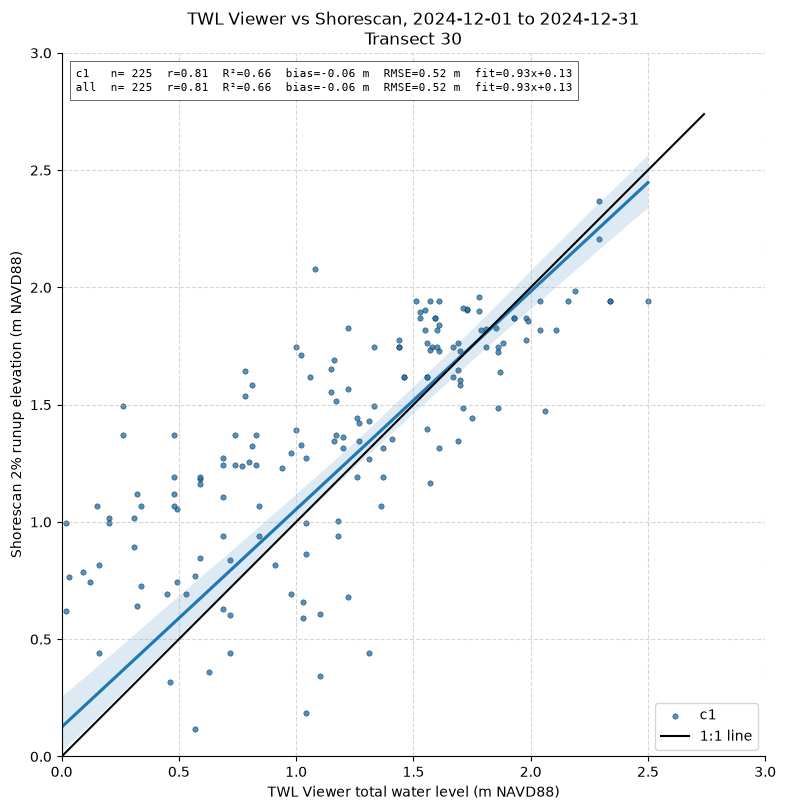

Transect 40
         n      r     R2   bias   rmse  slope  intercept
c1   182.0  0.578  0.334 -0.025  0.658  0.634       0.44
all  182.0  0.578  0.334 -0.025  0.658  0.634       0.44



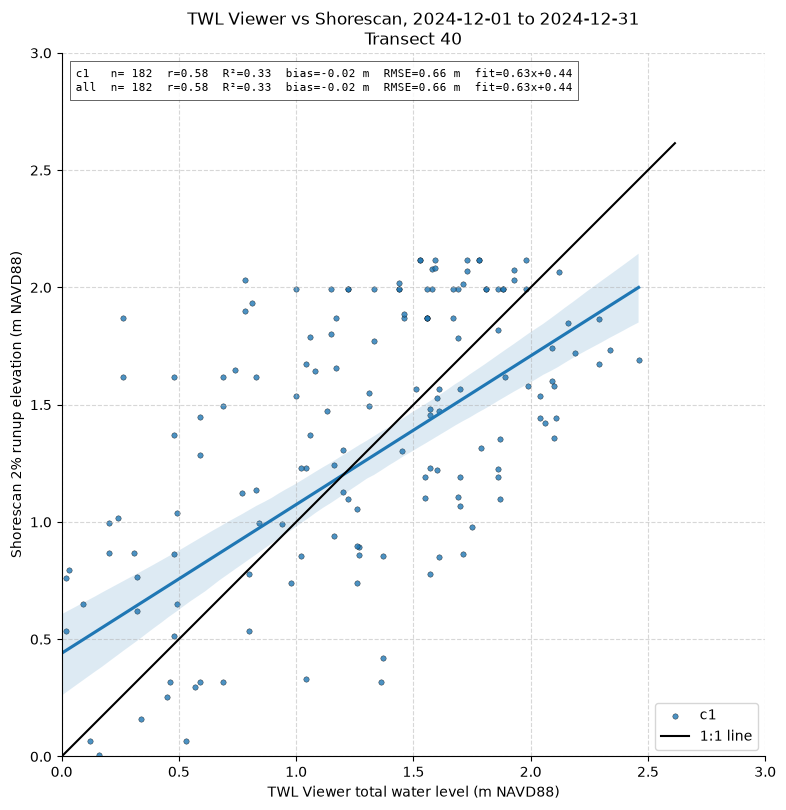

Transect 50
         n      r     R2   bias   rmse  slope  intercept
c1   152.0  0.422  0.178  0.256  0.814  0.459      0.405
all  152.0  0.422  0.178  0.256  0.814  0.459      0.405



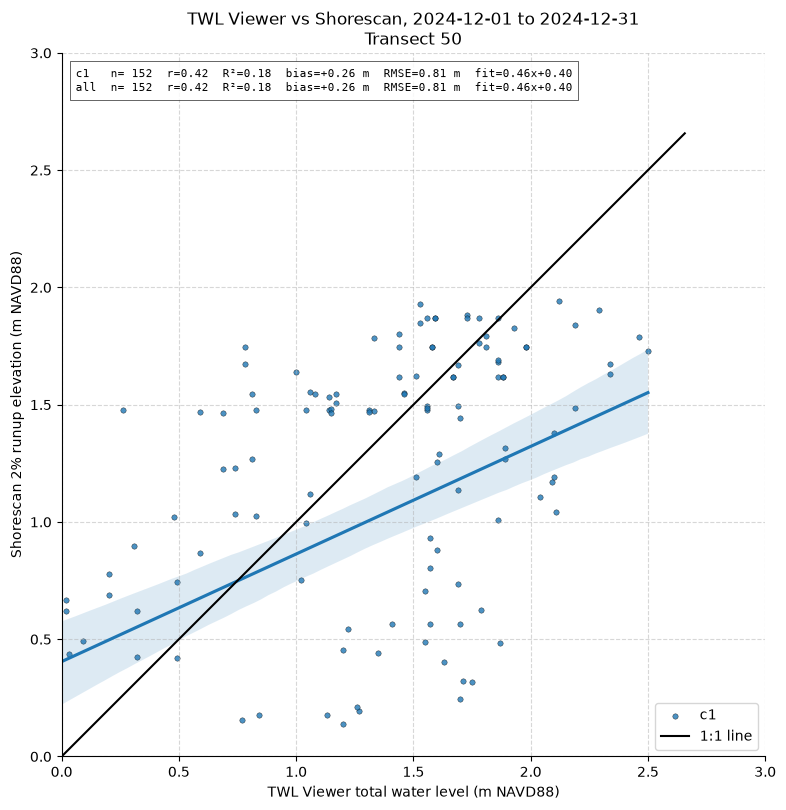

Transect 70
        n      r    R2   bias   rmse  slope  intercept
c1   54.0  0.889  0.79  0.073  0.367  0.576      0.169
all  54.0  0.889  0.79  0.073  0.367  0.576      0.169



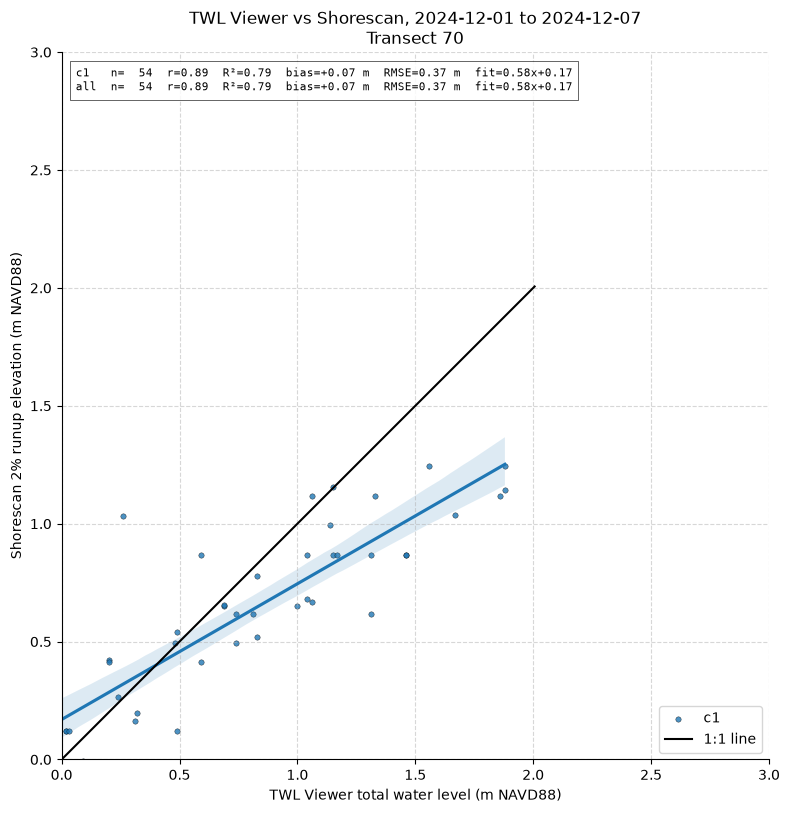

Skipping transect 100: no used bursts in 20241201-20241231
Skipping transect 150: no used bursts in 20241201-20241231


In [20]:
def fit_stats(fc, obs):
    """n, r, R2, bias, RMSE and the obs-on-fc fit for paired values."""
    ok = np.isfinite(fc) & np.isfinite(obs)
    fc, obs = np.asarray(fc)[ok], np.asarray(obs)[ok]
    if fc.size < 3:
        return pd.Series({"n": fc.size})
    err = fc - obs
    r = np.corrcoef(fc, obs)[0, 1]
    slope, intercept = np.polyfit(fc, obs, 1)
    return pd.Series({"n": fc.size, "r": r, "R2": r**2, "bias": err.mean(),
                      "rmse": np.sqrt((err**2).mean()), "slope": slope,
                      "intercept": intercept})


def stats_box(ax, df, x, y, group, order=None, all_df=None):
    """Write per-group and overall fit statistics in the top-left corner.

    all_df: rows for the "all" line when df repeats bursts across groups
    (cumulative mode); default df.
    """
    by_group = df.groupby(group).apply(
        lambda d: fit_stats(d[x], d[y]), include_groups=False)
    base = df if all_df is None else all_df
    table = pd.concat([by_group.reindex(order) if order else by_group,
                       fit_stats(base[x], base[y]).to_frame("all").T])
    w = max(len(str(name)) for name in table.index)  # align the columns
    lines = [f"{str(name):<{w}}  n={s.n:4.0f}" + (
             f"  r={s.r:.2f}  R²={s.R2:.2f}  bias={s.bias:+.2f} m  "
             f"RMSE={s.rmse:.2f} m  fit={s.slope:.2f}x{s.intercept:+.2f}"
             if s.n >= 3 else "") for name, s in table.iterrows()]
    ax.text(0.02, 0.98, "\n".join(lines), transform=ax.transAxes, va="top",
            fontsize=8, family="monospace",
            bbox={"fc": "white", "alpha": 0.85, "lw": 0.5})
    return table


scatter_kws = {"linewidths": 0.3, "s": 15, "alpha": 0.8, "edgecolor": "k"}

for transect in TRANSECTS:
    csv = data_dir / (f"Shorescan_TWL_viewer_Transect{transect}_ALLCAMERAS"
                      f"_sensor_{TAG}.csv")
    if not csv.exists():
        print(f"Skipping transect {transect}: {csv.name} not found")
        continue
    df_ss = pd.read_csv(csv)
    df_ss = df_ss[df_ss["use"] & in_date_range(df_ss["dt0_utc"])]  # Section 2b + range
    if df_ss.empty:
        print(f"Skipping transect {transect}: no used bursts in {DATE_TAG}")
        continue
    dt_local = pd.to_datetime(df_ss["dt0"], utc=True).dt.tz_convert(LOCAL_TZ)
    d0, d1 = dt_local.min().date(), dt_local.max().date()

    g = sns.lmplot(data=df_ss, x="cc_twl", y="ss_twl_2pct_peaks", hue="camera",
                   height=8, legend=False, scatter_kws=scatter_kws)
    ax = g.ax
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]),
            max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, color="black", linestyle="-", label="1:1 line")
    ax.set(xlim=[0,3], ylim=[0,3], aspect="equal",
           xlabel="TWL Viewer total water level (m NAVD88)",
           ylabel="Shorescan 2% runup elevation (m NAVD88)",
           title=f"TWL Viewer vs Shorescan, {d0} to {d1}\nTransect {transect}")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="lower right")
    table = stats_box(ax, df_ss, "cc_twl", "ss_twl_2pct_peaks", "camera")
    print(f"Transect {transect}\n{table.round(3)}\n")
    g.figure.tight_layout()
    out_png = plot_dir / f"TWLvSS_Transect{transect}_{TAG}.png"
    g.savefig(out_png, dpi=150)
    plt.show()

## 4. TWL Viewer vs. Shorescan, coloured by cumulative wave-power interval
Each burst is labelled with the cumulative wave-power interval it falls in, then forecast TWL is compared with the
observed **2% runup elevation** (`ss_twl_2pct_peaks`, m NAVD88). As in Section 3, the mean runup elevation is not used:
the forecast `twl` is a 2% exceedance level, so the mean would sit about a swash height lower by design. Only bursts with
`use = True` are plotted.

**What an interval is.** `cumulativeWavePower_nbdc44013.ipynb` sums hourly wave power at NDBC 44013 forward and backward
from each survey date and records when the sum first passes 200, 400 and 600 kWh/m. For one survey and one threshold, the
interval runs from the backward crossing to the forward crossing, i.e. the time around the survey with less than that much
wave energy on each side. Intervals are therefore **nested** (200 ⊂ 400 ⊂ 600 for the same survey).

**Two ways to group the bursts (`THRESH_MODE`).**
- `"band"`: each burst goes in one group, the **smallest** threshold whose interval contains it, so the groups are
  0–200, 200–400 and 400–600 kWh/m. The groups don't share bursts, so their statistics are independent. This is what the
  Section 5 shading shows.
- `"cumulative"`: each group holds **every** burst within that threshold's interval, so the groups are 0–200, 0–400 and
  0–600 kWh/m and a burst near a survey appears in all three. This shows how skill changes as more energetic conditions
  are included, but the groups overlap, so their statistics are not independent and differences between them partly
  repeat the same bursts.

Either way, the "all" line in the stats box counts every used burst once, and bursts beyond the largest interval form an
"outside intervals" group. If a threshold was not reached within the 21-day search window
(`datetime_crossed` empty), that side of the interval is set to the window edge (`THRESH_WINDOW_DAYS`).

**Time zone.** The crossing times come straight from the NDBC 44013 file index, and NDBC writes both real-time and
historical data **in UTC only** (https://www.ndbc.noaa.gov/faq/measdes.shtml). Neither the threshold notebook nor
`waveDataDownloader.ipynb` (which builds the times from NDBC's `YY MM DD hh mm` columns) converts them, so the crossing
times are **UTC** (checked 2026-11-03). The survey dates are treated as 00:00 UTC, as in the threshold notebook. Since the
2026-11-03 update to that notebook, crossing times are interpolated between buoy samples, to the minute.

In [19]:
THRESH_FILE = Path(r"..\DATA\cumulative_power_thresholds_2024-10-01-2025-03-31.csv")
THRESH_TZ = "UTC"  # NDBC times are UTC; the downloader does not convert them
THRESH_WINDOW_DAYS = 21  # LOOKBACK_DAYS / LOOKFWD_DAYS in the threshold notebook
THRESH_MODE = "cumulative"  # "band": 0-200, 200-400, 400-600 (each burst once)
#                      "cumulative": 0-200, 0-400, 0-600 (groups overlap)
THRESH_COLORS = {200: "skyblue", 400: "darkblue", 600: "red"}
OUTSIDE_COLOR = "lightgray"

df_thresh = pd.read_csv(THRESH_FILE)


def to_utc(values):
    """Parse times; naive ones are taken to be in THRESH_TZ."""
    t = pd.to_datetime(values)
    return (t.dt.tz_localize(THRESH_TZ) if t.dt.tz is None else t).dt.tz_convert("UTC")


df_thresh["t_crossed_utc"] = to_utc(df_thresh["datetime_crossed"])
df_thresh["t_survey_utc"] = to_utc(df_thresh["survey_date"])

# Pair each survey's backward and forward crossing for the same threshold.
# Pivoting on (survey, threshold) does this by key rather than by row order,
# so a reordered or partly missing file can't mismatch them.
wide = df_thresh.pivot_table(index=["survey_date", "threshold_kWh_m"],
                             columns="direction", values="t_crossed_utc",
                             aggfunc="first")
survey = wide.index.get_level_values("survey_date")
survey_utc = to_utc(pd.Series(survey)).to_numpy()
window = pd.Timedelta(days=THRESH_WINDOW_DAYS)
intervals_df = pd.DataFrame({
    "survey": survey,
    "thresh": wide.index.get_level_values("threshold_kWh_m"),
    "start": wide.get("backward"), "end": wide.get("forward")}).reset_index(drop=True)
open_start, open_end = intervals_df["start"].isna(), intervals_df["end"].isna()
intervals_df["start"] = intervals_df["start"].fillna(pd.Series(survey_utc - window))
intervals_df["end"] = intervals_df["end"].fillna(pd.Series(survey_utc + window))
if open_start.any() or open_end.any():
    print(f"{int(open_start.sum() + open_end.sum())} crossings not reached within "
          f"{THRESH_WINDOW_DAYS} days; set to the window edge")

# Smallest threshold first, so the label below picks the tightest interval.
intervals_df = intervals_df.sort_values(["thresh", "start"], ignore_index=True)
intervals_df

,survey,thresh,start,end
0,2024-10-23,200,2024-10-19 12:00:00+00:00,2024-10-25 18:00:00+00:00
1,2025-01-23,200,2025-01-20 10:00:00+00:00,2025-01-30 00:00:00+00:00
2,2025-02-19,200,2025-02-17 22:00:00+00:00,2025-02-23 09:00:00+00:00
3,2025-03-06,200,2025-03-01 09:00:00+00:00,2025-03-07 11:00:00+00:00
4,2024-10-23,400,2024-10-18 19:00:00+00:00,2024-10-26 20:00:00+00:00
5,2025-01-23,400,2025-01-17 15:00:00+00:00,2025-02-01 16:00:00+00:00
6,2025-02-19,400,2025-02-17 03:00:00+00:00,2025-02-28 17:00:00+00:00
7,2025-03-06,400,2025-02-25 08:00:00+00:00,2025-03-09 01:00:00+00:00
8,2024-10-23,600,2024-10-14 22:00:00+00:00,2024-11-01 14:00:00+00:00
9,2025-01-23,600,2025-01-14 04:00:00+00:00,2025-02-02 02:00:00+00:00


In [51]:
# df_ss = pd.read_csv(data_dir / f"Shorescan_TWL_viewer_{TAG}.csv")
df_ss = pd.read_csv(f"C:\\Users\\cvolp\\shorescan_processing\\output_plots\\Dec_2024_noTWLrecompute\\processed\\Shorescan_TWL_viewer_{TAG}.csv")
df_ss["dt0_utc"] = pd.to_datetime(df_ss["dt0_utc"], utc=True)
df_ss = df_ss[in_date_range(df_ss["dt0_utc"])].reset_index(drop=True)
DATESTART = "2024-12-01"   # first day kept (inclusive); None = no lower limit
DATEEND = "2024-12-24"     # last day kept (inclusive); None = no upper limit
# Compare every burst time with every interval at once: an n_bursts x
# n_intervals True/False table (1,673 x a few intervals = a few kB), far
# cheaper than a cross-join, which copies every CSV column per interval.
# Times are compared as UTC numbers, not text, so -04:00/-05:00 offsets
# can't break it.
t = df_ss["dt0_utc"].to_numpy()
inside = ((t[:, None] >= intervals_df["start"].to_numpy()[None, :])
          & (t[:, None] <= intervals_df["end"].to_numpy()[None, :]))
thr_of_interval = intervals_df["thresh"].to_numpy()
thresholds = np.sort(np.unique(thr_of_interval))
lower = dict(zip(thresholds, np.r_[0, thresholds[:-1]]))

# Band: smallest threshold whose interval contains the burst (intervals are
# sorted by threshold, so argmax finds it).
first = inside.argmax(axis=1)
df_ss["thresh"] = np.where(inside.any(axis=1), thr_of_interval[first], np.nan)

# Group membership, one column per threshold:
#   band       -> the burst's own band only
#   cumulative -> any interval with threshold <= T
if THRESH_MODE == "band":
    member = df_ss["thresh"].to_numpy()[:, None] == thresholds[None, :]
    names = [f"{lower[T]:.0f}–{T:.0f} kWh/m" for T in thresholds]
elif THRESH_MODE == "cumulative":
    member = np.column_stack([inside[:, thr_of_interval <= T].any(axis=1)
                              for T in thresholds])  # one column per threshold
    names = [f"0–{T:.0f} kWh/m" for T in thresholds]
else:
    raise ValueError('THRESH_MODE must be "band" or "cumulative"')

# Long table: one row per (burst, group). np.nonzero lists every True cell,
# so a burst in three cumulative groups becomes three rows.
rows, cols = np.nonzero(member)
OUTSIDE = "outside intervals"
outside = np.flatnonzero(~inside.any(axis=1))
df_groups = pd.concat([
    df_ss.iloc[rows].assign(thresh_label=np.array(names)[cols],
                            thresh_key=thresholds[cols]),
    df_ss.iloc[outside].assign(thresh_label=OUTSIDE, thresh_key=np.nan)],
    ignore_index=True)
group_order = names + [OUTSIDE]
df_ss["thresh_label"] = df_ss["thresh"].map(
    {T: n for T, n in zip(thresholds, [f"{lower[T]:.0f}–{T:.0f} kWh/m"
                                       for T in thresholds])}).fillna(OUTSIDE)

n_overlap = int((inside.sum(axis=1) > 1).sum())
print(f"Mode: {THRESH_MODE}. {df_ss['thresh'].notna().sum()} of {len(df_ss)} "
      f"bursts fall in an interval ({n_overlap} in more than one).")
print(df_groups["thresh_label"].value_counts().reindex(group_order).to_string())

Mode: cumulative. 0 of 957 bursts fall in an interval (0 in more than one).
thresh_label
0–200 kWh/m            NaN
0–400 kWh/m            NaN
0–600 kWh/m            NaN
outside intervals    957.0


                       n     r     R2   bias   rmse  slope  intercept
outside intervals  898.0  0.56  0.314 -0.008  0.782  0.657      0.341
all                898.0  0.56  0.314 -0.008  0.782  0.657      0.341


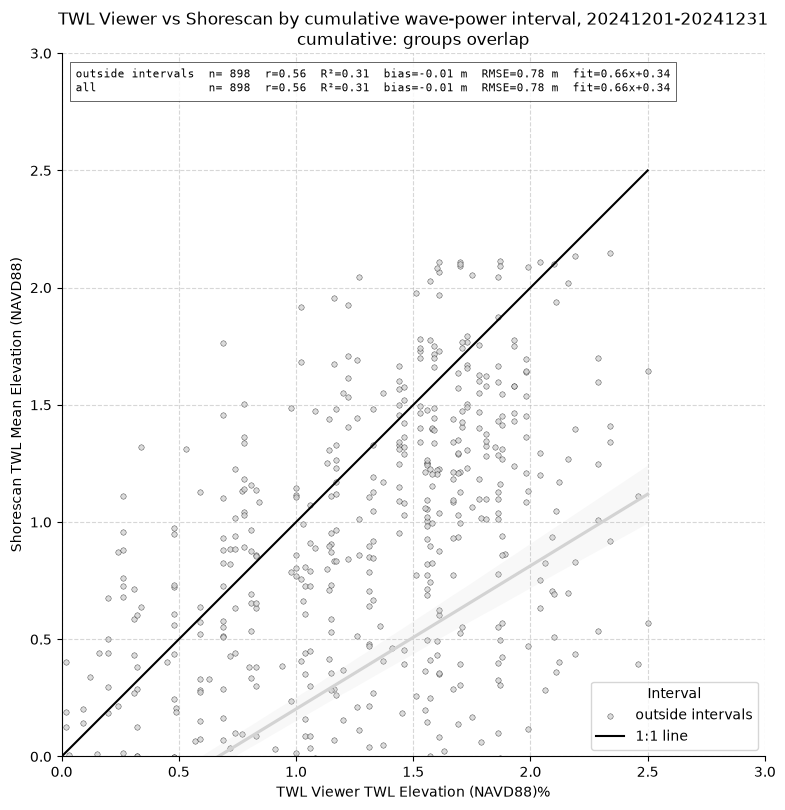

In [52]:
# plot_groups = df_groups[df_groups["use"]].dropna(subset=["cc_twl", "ss_twl_2pct_peaks"])
# plot_unique = df_ss[df_ss["use"]].dropna(subset=["cc_twl", "ss_twl_2pct_peaks"])

plot_groups = df_groups.dropna(subset=["cc_twl", "ss_twl_mean"])
plot_unique = df_ss.dropna(subset=["cc_twl", "ss_twl_mean"])

colour_of = dict(zip(names, [THRESH_COLORS.get(int(T), "tab:purple")
                             for T in thresholds]))
colour_of[OUTSIDE] = OUTSIDE_COLOR
order = [g for g in group_order if g in set(plot_groups["thresh_label"])]
# Cumulative groups overlap, so draw the widest first and the narrowest on top.
draw_order = (order if THRESH_MODE == "band"
              else [OUTSIDE] * (OUTSIDE in order) + [g for g in order if g != OUTSIDE][::-1])

g = sns.lmplot(data=plot_groups, x="cc_twl",y="ss_twl_mean",
               hue="thresh_label", hue_order=draw_order, palette=colour_of,
               height=8, legend=False,
               scatter_kws={"linewidths": 0.3, "s": 15, "alpha": 0.8,
                            "edgecolor": "k"})
ax = g.ax
vals = plot_unique[["cc_twl", "ss_twl_mean"]].to_numpy()
lims = [np.floor(vals.min() * 2) / 2, np.ceil(vals.max() * 2) / 2]
ax.plot(lims, lims, color="black", linestyle="-", label="1:1 line")
ax.set(xlim=[0,3], ylim=[0,3], aspect="equal",
       xlabel="TWL Viewer TWL Elevation (NAVD88)%",
       ylabel="Shorescan TWL Mean Elevation (NAVD88)",
       title=(f"TWL Viewer vs Shorescan by cumulative wave-power interval, {DATE_TAG}\n"
              + ("bands: each burst once" if THRESH_MODE == "band"
                 else "cumulative: groups overlap")))
ax.grid(True, linestyle="--", alpha=0.5)
handles, labels = ax.get_legend_handles_labels()
keep = sorted(range(len(labels)),  # legend in group order, 1:1 line last
              key=lambda i: order.index(labels[i]) if labels[i] in order else 99)
ax.legend([handles[i] for i in keep], [labels[i] for i in keep],
          title="Interval", loc="lower right")
# Same statistics as Section 3; "all" uses each burst once.
stats_thresh = stats_box(ax, plot_groups, "cc_twl", "ss_twl_2pct_peaks",
                         "thresh_label", order, all_df=plot_unique)
print(stats_thresh.round(3))
g.figure.tight_layout()
g.savefig(plot_dir / f"TWLvSS_twl_mean_{THRESH_MODE}_{TAG}.png", dpi=150)
plt.show()

## 5. Time series with wave-power interval shading
Background shading shows which cumulative wave-power band each moment falls in, in the same colours as Section 4
(e.g. 0–200 kWh/m is the time around a survey with less than 200 kWh/m of wave energy on either side). Dashed lines mark
the survey dates. Panels, top to bottom:
1. **Significant wave height.** From `HS_FILE` if set (e.g. your nearshore PUV record, any CSV with a time column and an
   Hs column; values ≥ `HS_FILL_MIN` are treated as fill), otherwise the TWL Viewer forecast Hs at each burst.
   The x-axis covers the bursts and the intervals, not the whole Hs record.
2. **Water levels.** Forecast TWL (line) and the observed 2% runup elevation (dots), m NAVD88.
3. **Error.** Forecast − observed TWL; above zero means the forecast was too high.

`TS_CAMERA` / `TS_TRANSECT` pick one transect; set `TS_TRANSECT = None` to use the alongshore median of all
non-clipped transects at each burst time.

**Coding notes.**
- *Clean shading where intervals overlap.* Intervals from neighbouring surveys can overlap (Feb 19 and Mar 6 here).
  Drawing each one as a transparent box would mix colours. Instead, every 10 minutes of the plotted period is labelled
  once, with the same "smallest threshold" rule as Section 4, and each band is shaded with a single `fill_between` call
  (`where=` picks the times in that band; `transform=ax.get_xaxis_transform()` makes it span the full panel height).
  The 10-min grid × intervals comparison is a few hundred kB, so it is fast.
- *Gaps.* `asfreq("30min")` puts empty rows into the 30-min burst record where there were no bursts (nights, missing
  days), so lines break there instead of drawing straight across.
- *Time zone.* Data stay in UTC; `DateFormatter(..., tz=LOCAL_TZ)` labels the axis in Eastern time.

C:\Users\cvolp\AppData\Local\Temp\ipykernel_2876\4281526305.py:110: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[2].legend()


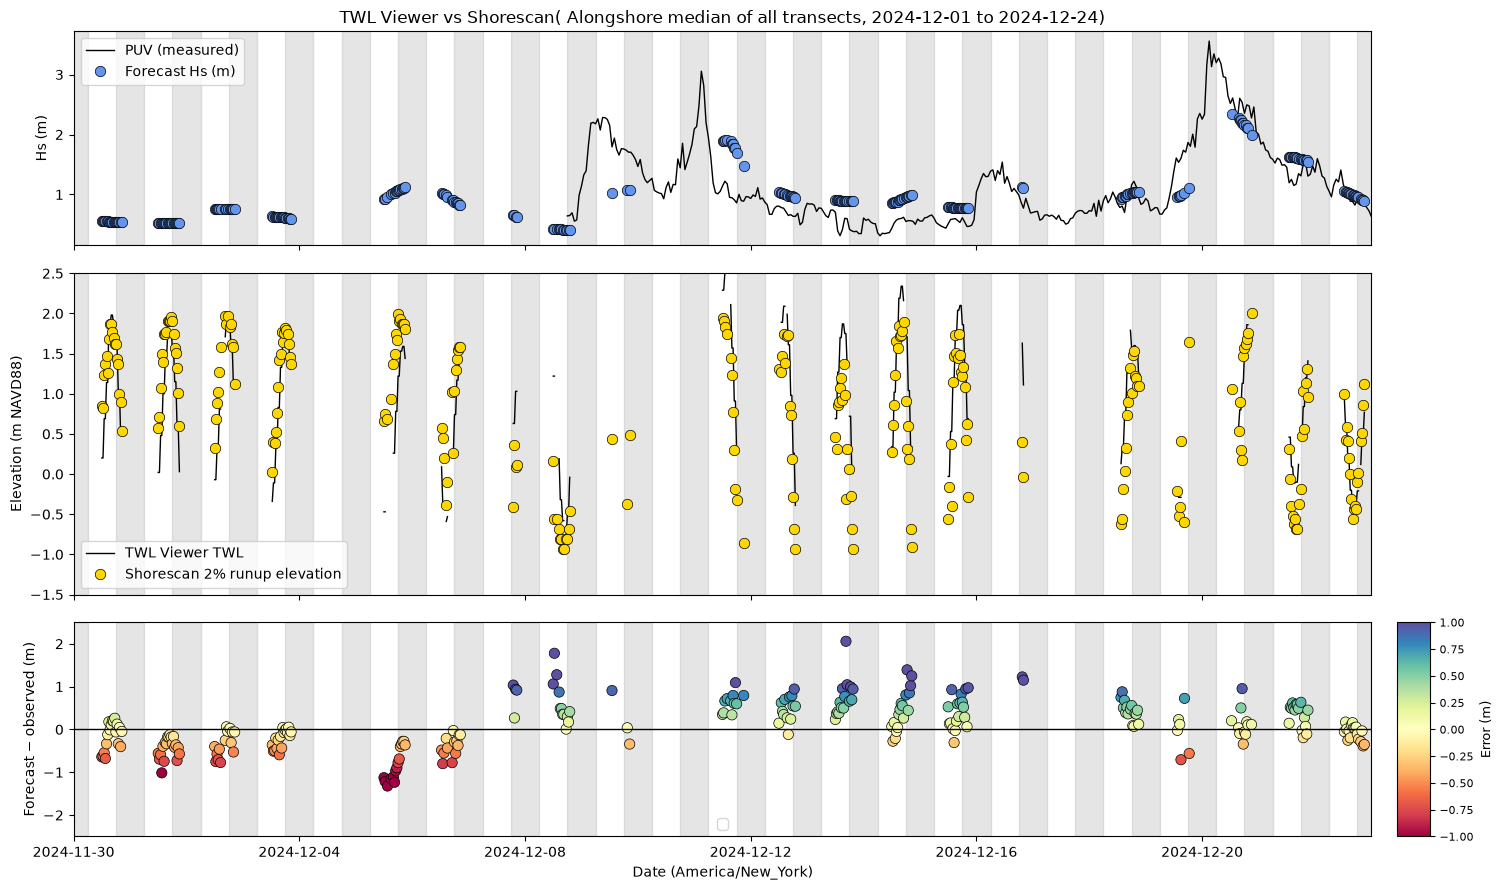

In [113]:
from matplotlib.patches import Patch
import matplotlib.dates as mdates

TS_CAMERA, TS_TRANSECT = "c1", None  # TS_TRANSECT = None -> alongshore median
# HS_FILE = None        # e.g. Path(".../puv_waves.csv"); None -> forecast Hs at bursts
# Continuous forecast Hs instead: the best estimate from get_TWL_forecast.ipynb,
# HS_FILE = Path("../DATA/sig1000_waves_ALL.csv"), 

HS_TIME_COL1, HS_COL1 = "valid_time_utc", "hs"
# HS_TIME_COL, HS_COL = "datetime", "Hs"
HS_TIME_COL = "time"
HS_COL= "wh_4061"
HS_NAME = "measured"  # label for HS_FILE in the y-axis, e.g. "PUV"
HS_TZ = "UTC"         # zone of HS_TIME_COL if it has no offset written in it
HS_FILL_MIN = 99.0    # Hs at or above this is a fill value (NDBC uses 99.00)
SHADE_ALPHA = 0.35

# --- Observed and forecast series at burst times ---------------------------
 # reset in case the QC section was run before this one 
df_all = df_ss
ok = df_all["use"]
if TS_TRANSECT is None:
    sel, title_sel = ok, " Alongshore median of all transects"
else:
    sel = ok & (df_all["camera"] == TS_CAMERA) & (df_all["transect"] == TS_TRANSECT)
    title_sel = f"{TS_CAMERA} transect {TS_TRANSECT}"
ts = (df_all.loc[sel, ["dt0_utc", "cc_twl", "ss_twl_2pct_peaks", "cc_Hs"]]
      .groupby("dt0_utc").median()      # one row per burst time
      # .asfreq("30min"))  # 2026-11-16: asfreq keeps only rows exactly on the grid; an off-grid burst was dropped
      .resample("30min").mean())        # 30-min bins; empty bins (nights, missing days) stay NaN
ts["err"] = ts["cc_twl"] - ts["ss_twl_2pct_peaks"]

if HS_FILE is not None:
    hs = pd.read_csv("../DATA/sig1000_waves_ALL.csv") #, usecols=[HS_TIME_COL, HS_COL])
    t_hs = pd.to_datetime(hs[HS_TIME_COL])
    t_hs = t_hs.dt.tz_localize(HS_TZ) if t_hs.dt.tz is None else t_hs
    hs_vals = pd.to_numeric(hs[HS_COL], errors="coerce")
    hs_vals = hs_vals.where((hs_vals >= 0) & (hs_vals < HS_FILL_MIN))  # fills -> NaN
    hs_series1 = (pd.Series(hs_vals.to_numpy(), index=t_hs.dt.tz_convert("UTC"))
                 .dropna().sort_index())
    hs_label2 = f"Hs, {HS_NAME} (m)"
    hs_series2, hs_label2 = ts["cc_Hs"], "Hs, TWL Viewer forecast (m)"
else:
    hs_series, hs_label = ts["cc_Hs"], "Hs, TWL Viewer forecast (m)"

# --- Label a 10-min grid with its wave-power band ---------------------------
t_lo = min(intervals_df["start"].min(), ts.index.min())
t_hi = max(intervals_df["end"].max(), ts.index.max())
t_lo, t_hi = max(t_lo, T_START), min(t_hi, T_STOP)   # stay inside the date range
grid = pd.date_range(t_lo.floor("D"), t_hi.ceil("D"), freq="3min")
g = grid.to_numpy()
inside = ((g[:, None] >= intervals_df["start"].to_numpy()[None, :])
          & (g[:, None] <= intervals_df["end"].to_numpy()[None, :]))
band = np.where(inside.any(axis=1),
                intervals_df["thresh"].to_numpy()[inside.argmax(axis=1)], np.nan)

thresholds = sorted(intervals_df["thresh"].unique())
lower = dict(zip(thresholds, [0] + thresholds[:-1]))  # band's lower edge
surveys = pd.to_datetime(intervals_df["survey"].unique()).tz_localize(THRESH_TZ)
surveys = surveys[(surveys >= t_lo) & (surveys <= t_hi)]

# --- Add "night" shaded patches
dates = pd.date_range(t_lo, t_hi,freq="h")
values = np.sin(np.linspace(0, 6 * np.pi, len(dates)))
start_day = dates.min().floor("D") - pd.Timedelta(days=1)
end_day = dates.max().ceil("D")
# --- Plot ------------------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True,
                         gridspec_kw={"height_ratios": [2, 3, 2]})
for ax in axes:
    for thr in thresholds:
        ax.fill_between(grid, 0, 1, where=band == thr, lw=0,
                        color=THRESH_COLORS.get(int(thr), "tab:purple"),
                        alpha=SHADE_ALPHA, transform=ax.get_xaxis_transform())
    for t in surveys:
        ax.axvline(t, color="k", ls="--", lw=1)

    for day in pd.date_range(start_day, end_day, freq="D"):
        night_start = day + pd.Timedelta(hours=18)
        night_end = day + pd.Timedelta(days=1, hours=6)
        ax.axvspan(night_start, night_end, color="gray", alpha=0.2, zorder=0)

hs_plot1 = hs_series1.loc[t_lo:t_hi]  # only the plotted period
hs_plot2 = hs_series2.loc[t_lo:t_hi]
# A continuous record is drawn as a line; burst-only forecast Hs as dots.
axes[0].plot(hs_plot1.index, hs_plot1, ".-" if HS_FILE is None else "-",
             color="k", lw=1, ms=3,label="PUV (measured)")
axes[0].plot(hs_plot2.index,hs_plot2, ".", markersize=15,markeredgecolor='black',markeredgewidth=0.5, color = "cornflowerblue",label="Forecast Hs (m)")
axes[0].set_ylabel("Hs (m)")
axes[0].legend()

axes[1].plot(ts.index, ts["cc_twl"], color="k", lw=1,
             label="TWL Viewer TWL")
axes[1].plot(ts.index, ts["ss_twl_2pct_peaks"], ".", color="gold", ms=15,markeredgecolor="black", markeredgewidth=0.5,
             label="Shorescan 2% runup elevation")
axes[1].set_ylabel("Elevation (m NAVD88)")
axes[1].set_ylim(-1.5, 2.5)
axes[1].legend()
magnitude = ts["err"]

axes[2].axhline(0, color="k", lw=1)
sc = axes[2].scatter(ts.index, ts["err"],c=magnitude, cmap='Spectral',vmin=-1,vmax=1, s=55,edgecolors="black",linewidth=0.5)

axes[2].set_ylabel("Forecast − observed (m)")
axes[2].set_xlabel(f"Date ({LOCAL_TZ})")
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d", tz=LOCAL_TZ))
axes[2].set_xlim([pd.Timestamp(DATESTART),pd.Timestamp(DATEEND)])
# axes[2].set_xlim(grid[0], grid[-1])  # bursts + intervals, not the whole Hs record
axes[2].set_ylim(-2.5, 2.5)
axes[2].legend()
cax = axes[2].inset_axes([1.02, 0.0, 0.025, 1.0])

# Attach colorbar to cax
cbar = fig.colorbar(sc, cax=cax, orientation='vertical')
cbar.set_label('Error (m)', fontsize=9)
cbar.ax.tick_params(labelsize=8)



#shade = [Patch(color=THRESH_COLORS.get(int(t), "tab:purple"), alpha=SHADE_ALPHA,
            #    label=f"{lower[t]:.0f}–{t:.0f} kWh/m") for t in thresholds]
shade = [Patch(color='gray', alpha = 0.3, label = "Night Hours (18:00-6:00)")]
lines, labels = axes[1].get_legend_handles_labels()
# axes[1].legend(shade + lines + [plt.Line2D([], [], color="k", ls="--")],
#                [p.get_label() for p in shade] + labels + ["Survey date"],
#                loc="upper right", ncol=3, fontsize=10)
axes[0].set_title("TWL Viewer vs Shorescan"
                  f"({title_sel}, {DATESTART} to {DATEEND})")
fig.tight_layout()


fig.savefig(plot_dir / f"TWLvSS_timeseries_thresholds_{TAG}.png", dpi=150)
plt.show()